# Gauss–Newton 方法

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

既然第07章把非线性残差局部近似为$r+Jh$，最自然的下一步就是把这个线性最小二乘问题解掉，再更新参数。

## 推导一步更新

$$h_{\rm GN}=\arg\min_h\|Jh+r\|^2,\qquad x_{\rm new}=x+h_{\rm GN}.$$

满列秩时等价于$J^TJh=-J^Tr$。实现直接对$J$使用最小二乘，避免形成正规方程。它相当于用$J^TJ$近似Hessian，省略了$\sum_i r_i\nabla^2r_i$。

当残差接近零且局部雅可比满秩时，GN往往很快。大残差、坏初值或强曲率会使局部线性模型失真；此时满步长可能让真实目标大幅上升。

## 先写一个未经保护的GN循环

Rosenbrock残差$r=(10(x_2-x_1^2),\,1-x_1)^T$的最小值在$(1,1)$。从$(-1.2,1)$开始，观察第一步目标如何变化。

unprotected full-step costs: [  12.1  1171.28    0.      0.      0.      0.      0.  ]
safeguarded estimate/status: [1. 1.] gradient


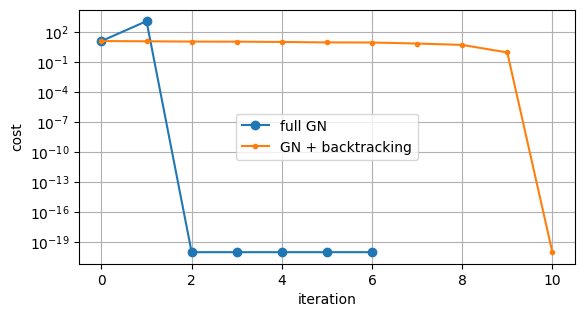

In [2]:
def rfun(x):
    return np.array([10*(x[1]-x[0]**2), 1-x[0]])
def jfun(x):
    return np.array([[-20*x[0], 10.], [-1., 0.]])
x = np.array([-1.2, 1.])
raw = [.5*rfun(x)@rfun(x)]
for _ in range(6):
    h = np.linalg.lstsq(jfun(x), -rfun(x), rcond=None)[0]
    x = x+h
    raw.append(.5*rfun(x)@rfun(x))
print('unprotected full-step costs:', np.array(raw))
assert raw[1] > raw[0]
safe = gauss_newton(rfun, jfun, [-1.2,1.])
print('safeguarded estimate/status:', safe.x, safe.status)
costs = [p['cost'] for p in safe.history]
plt.semilogy(np.maximum(raw, 1e-20), 'o-', label='full GN')
plt.semilogy(np.maximum(costs, 1e-20), '.-', label='GN + backtracking')
plt.xlabel('iteration'); plt.ylabel('cost'); plt.legend(); plt.show()
assert np.allclose(safe.x, [1,1], atol=1e-6)

## 给方向加上回溯保护

解出$h$后，检验$F(x+\alpha h)$，必要时将$\alpha$减半。线性模型没有变，只是承认它在太远处可能不可信。第08章的方向与步长分工在这里直接复用。

下面拟合真实目标非零的指数观测，并与SciPy比较。此时“拟合成功”不意味着所有残差都变成零，噪声会留下不可消除的误差。

ours: [2.50686 0.80254 0.4034 ] gradient cost: 0.013858140938455986
SciPy: [2.50686 0.80254 0.4034 ] cost: 0.013858140938455986


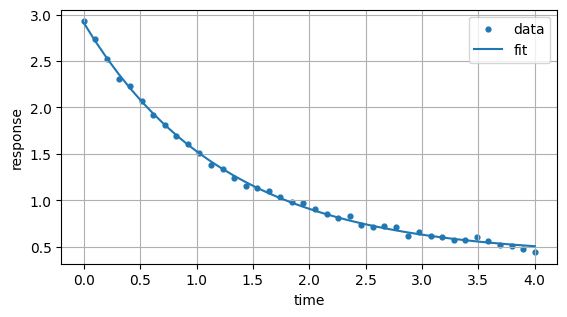

In [3]:
rng = np.random.default_rng(109)
t = np.linspace(0, 4, 40)
y = 2.5*np.exp(-.8*t)+.4+rng.normal(0,.035,len(t))
def residual(p):
    return p[0]*np.exp(-p[1]*t)+p[2]-y
def jac(p):
    e = np.exp(-p[1]*t)
    return np.column_stack([e,-p[0]*t*e,np.ones_like(t)])
ours = gauss_newton(residual, jac, [2., .5, .2], gtol=1e-8)
reference = least_squares(residual,[2., .5, .2],jac=jac,gtol=1e-12,ftol=1e-12,xtol=1e-12)
print('ours:', ours.x, ours.status, 'cost:', ours.cost)
print('SciPy:', reference.x, 'cost:', reference.cost)
assert np.allclose(ours.x, reference.x, atol=2e-5)
plt.scatter(t,y,s=12,label='data'); plt.plot(t,residual(ours.x)+y,label='fit')
plt.xlabel('time'); plt.ylabel('response'); plt.legend(); plt.show()

## 何时不该继续硬走GN

若雅可比近秩亏，局部步可能很大；若参数差好几个数量级，某些坐标会主导步长；若噪声使局部线性化不稳定，频繁回溯会很慢。可以改善参数化、缩放、增加信息，或用LM和信赖域限制步长。求解器不能修复完全不可辨识的模型。

## 练习与解答

练习：在线性残差$r=Ax-y$下，GN需要几次有效更新？解答：精确运算、满秩且采用完整步时一次到达最小二乘解，因为局部模型就是原问题。

练习：GN能否用于$m<n$？解答：线性子问题可求最小范数步，但存在未被观测约束的参数方向，不能声称解唯一；需要先验、约束或更多信息。

练习：上图中未经保护GN最后也到达了解，为什么仍需保护？解答：中间的大幅上升在其他模型里可能触发溢出、离开物理范围或进入错误吸引域，最终碰巧成功不是可靠策略。